In [1]:
import numpy as np
import anndata as ad
import pandas as pd
from umap import UMAP

In [2]:
test_dataset = ad.read_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_consolidated.h5ad')
test_dataset.obs['barcode'] = test_dataset.obs['cell_ID'].astype(str) + '_'+ test_dataset.obs['sample'].astype(str)
test_dataset.obs = test_dataset.obs.set_index('barcode')

In [3]:
x_mask = (test_dataset.X.sum(axis=1)>10)&(test_dataset.obs['Tissue']=='tumor').values
x_mask.shape

(173954,)

In [4]:
test_dataset = test_dataset[x_mask]

In [5]:
test_dataset.obs['Tissue'].value_counts()

Tissue
tumor    40359
Name: count, dtype: int64

In [6]:
test_dataset.obs['sample'].unique()

['p1t1', 'p1t2', 'p1t3', 'p1t4', 'p2t1', ..., 'p5t2', 'p6t1', 'p6t2', 'p7t1', 'p7t2']
Length: 18
Categories (18, object): ['p1t1', 'p1t2', 'p1t3', 'p1t4', ..., 'p6t1', 'p6t2', 'p7t1', 'p7t2']

In [7]:
test_dataset.obs['tissue'] = test_dataset.obs['sample']

/tmp/ipykernel_3655788/1290730347.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  test_dataset.obs['tissue'] = test_dataset.obs['sample']


(0.0, 1000.0)

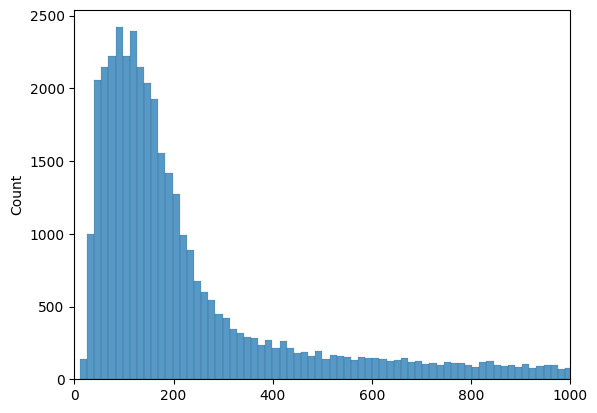

In [8]:
import seaborn as sns

ax = sns.histplot(x=test_dataset.X.sum(axis=1))
ax.set_xlim([0,1000])

In [11]:
test_dataset.shape

(40359, 958)

In [12]:
import random
import scipy.stats as stats
from scipy.sparse import csc_matrix,csr_matrix
from tqdm.notebook import tqdm

# sample transcripts without replacement from one cell
def sample_transcripts(x_transcripts, frac=0.05, rng=None,seed=None):
    if rng is None:
        rng = np.random.default_rng(seed=seed)
    total = int(x_transcripts.sum())
    n = int(round(frac * total))
    added_vec = np.zeros_like(x_transcripts,dtype=int)
    if n < 10:
        return added_vec
    
    # sample only from non-zero transcripts!!
    nz_ids = np.nonzero(x_transcripts)
    sampled = stats.multivariate_hypergeom(x_transcripts[nz_ids],n=n).rvs(random_state=rng)
    
    added_vec[nz_ids] = sampled

    return added_vec

# map cell names to row indices
name_to_idx = {k: i for i, k in enumerate(test_dataset.obs_names)}

# PARAMETERS
K_SURROUNDING = 3
FRAC = 0.05
SEED = None
N_REPS = 10

(n_cells, n_genes) = test_dataset.X.shape
test_dataset.obs[["ADM_ID_%d" % i for i in range(K_SURROUNDING)]] = ''
X_admixed = np.zeros((N_REPS, n_cells, n_genes), dtype='float32')

# initialize dictionary of tissue subsets
tissue_list = test_dataset.obs['tissue'].unique()
tissue_subsets = {tis:test_dataset[test_dataset.obs['tissue'] == tis].copy() for tis in tissue_list}

# iterate over tissue subsets
for rep in range(N_REPS):
    pbar = tqdm(tissue_list)
    for tissue in pbar:
        pbar.set_description("Processing %s" % tissue)
        tissue_df = tissue_subsets[tissue]
        cell_pbar = tqdm(range(len(tissue_df)),leave=False)
        for i in cell_pbar:
            cell_pbar.set_description(tissue_df.obs_names[i])
            # get query cell id and type
            query_cell_id = tissue_df.obs_names[i]
            query_celltype = tissue_df.obs['cell_type'][query_cell_id]
            
            # filter only cells with same tissue, different cell type
            surrounding_cells = tissue_df[ # same tissue
                                (tissue_df.obs_names != query_cell_id)& # not self
                                (tissue_df.obs['cell_type'] != query_celltype)&
                                (tissue_df.X.sum(1)>400)].obs_names # different cell types
            
            # sample K_SURROUNDING cells
            surrounding_cells = random.sample(list(surrounding_cells), K_SURROUNDING)
            
            if len(surrounding_cells) < K_SURROUNDING:
                print("SKIPPING")
                continue
            
            # sample transcripts w/out replacement from surrounding cells
            admix_vec = np.zeros(n_genes,dtype=int)
            surr_cell_sum = np.zeros(n_genes,dtype=int)
            for j,surr_cell in enumerate(surrounding_cells):
                
                # sample FRAC of transcripts
                test_dataset.obs.loc[query_cell_id,"ADM_ID_%d" % j] = surr_cell+"_%d"%0
                surr_cell_sum += test_dataset.X[name_to_idx[surr_cell]].astype(int)
            admix_vec += sample_transcripts(test_dataset.X[name_to_idx[surr_cell]].astype(int), frac=FRAC*K_SURROUNDING,seed=SEED).reshape(-1)
            if sum(admix_vec) == 0:
                print(query_cell_id)
                
            # add sampled transcripts to admixed layer
            X_admixed[rep,name_to_idx[query_cell_id]] = admix_vec 


  0%|          | 0/18 [00:00<?, ?it/s]

  0%|          | 0/2528 [00:00<?, ?it/s]

  0%|          | 0/2832 [00:00<?, ?it/s]

  0%|          | 0/1344 [00:00<?, ?it/s]

  0%|          | 0/1585 [00:00<?, ?it/s]

  0%|          | 0/256 [00:00<?, ?it/s]

... (180 outputs left out)

  0%|          | 0/2985 [00:00<?, ?it/s]

  0%|          | 0/2687 [00:00<?, ?it/s]

  0%|          | 0/3210 [00:00<?, ?it/s]

  0%|          | 0/2887 [00:00<?, ?it/s]

In [13]:
for i in range(N_REPS):
    rep = test_dataset.copy()
    if i == 0:
        rep.layers['admixed'] = X_admixed[i]
    
        rep.obs.index = rep.obs.index + "_%d"%i
        all_reps = rep
    else:
        rep.layers['admixed'] = X_admixed[i]
        rep.obs.index = rep.obs.index + "_%d"%i
        all_reps = ad.concat([all_reps, rep], join='outer')

In [14]:
all_reps.obs.sort_index()

,species,filename,sample,GSM_ID,cell_ID,Patient,Tissue,Barcoding emulsion,Library,Total counts,...,used_in_NSCLC_immune,used_in_NSCLC_non_immune,used_in_blood,Barcode,batch,cell_type,tissue,ADM_ID_0,ADM_ID_1,ADM_ID_2
barcode,,,,,,,,,,,,,,,,,,,,,
bcAAAA_p1t2_0,human,GSM3635279_human_p1t2_raw_counts,p1t2,GSM3635279,bcAAAA,p1,tumor,p1t,p1t2,24593.0,...,False,True,False,bcAAAA_p1t2,sc,tumor,p1t2,bcHPRZ_p1t2_0,bcHZRS_p1t2_0,bcHQTI_p1t2_0
bcAAAA_p1t2_1,human,GSM3635279_human_p1t2_raw_counts,p1t2,GSM3635279,bcAAAA,p1,tumor,p1t,p1t2,24593.0,...,False,True,False,bcAAAA_p1t2,sc,tumor,p1t2,bcHPRZ_p1t2_0,bcHZRS_p1t2_0,bcHQTI_p1t2_0
bcAAAA_p1t2_2,human,GSM3635279_human_p1t2_raw_counts,p1t2,GSM3635279,bcAAAA,p1,tumor,p1t,p1t2,24593.0,...,False,True,False,bcAAAA_p1t2,sc,tumor,p1t2,bcHPRZ_p1t2_0,bcHZRS_p1t2_0,bcHQTI_p1t2_0
bcAAAA_p1t2_3,human,GSM3635279_human_p1t2_raw_counts,p1t2,GSM3635279,bcAAAA,p1,tumor,p1t,p1t2,24593.0,...,False,True,False,bcAAAA_p1t2,sc,tumor,p1t2,bcHPRZ_p1t2_0,bcHZRS_p1t2_0,bcHQTI_p1t2_0
bcAAAA_p1t2_4,human,GSM3635279_human_p1t2_raw_counts,p1t2,GSM3635279,bcAAAA,p1,tumor,p1t,p1t2,24593.0,...,False,True,False,bcAAAA_p1t2,sc,tumor,p1t2,bcHPRZ_p1t2_0,bcHZRS_p1t2_0,bcHQTI_p1t2_0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
bcIKDH_p4t3_5,human,GSM3635294_human_p4t3_raw_counts,p4t3,GSM3635294,bcIKDH,p4,tumor,p4t,p4t3,1598.0,...,True,False,False,bcIKDH_p4t3,sc,T CD8+,p4t3,bcBSVY_p4t3_0,bcBVJM_p4t3_0,bcFUQU_p4t3_0
bcIKDH_p4t3_6,human,GSM3635294_human_p4t3_raw_counts,p4t3,GSM3635294,bcIKDH,p4,tumor,p4t,p4t3,1598.0,...,True,False,False,bcIKDH_p4t3,sc,T CD8+,p4t3,bcBSVY_p4t3_0,bcBVJM_p4t3_0,bcFUQU_p4t3_0
bcIKDH_p4t3_7,human,GSM3635294_human_p4t3_raw_counts,p4t3,GSM3635294,bcIKDH,p4,tumor,p4t,p4t3,1598.0,...,True,False,False,bcIKDH_p4t3,sc,T CD8+,p4t3,bcBSVY_p4t3_0,bcBVJM_p4t3_0,bcFUQU_p4t3_0


In [18]:
# test_dataset.layers['admixed'] = X_admixed
# test_dataset.layers['is_transcript_added'] = (test_dataset.layers['admixed']>0).astype(int)

all_reps.layers['is_transcript_added'] = (all_reps.layers['admixed']>0).astype(int)
all_reps.layers

Layers with keys: admixed, is_transcript_added

In [19]:
all_reps.obs['Patient'].value_counts()

Patient
p3    102790
p1     82890
p7     60970
p6     56720
p4     49560
p5     45760
p2      4900
Name: count, dtype: int64

In [22]:
all_reps.obs['split'] = 'train'

all_reps.obs.loc[all_reps.obs['Patient']=='p5','split'] = 'val'

In [23]:
all_reps.obs['split'].value_counts()

split
train    357830
val       45760
Name: count, dtype: int64

In [24]:
all_reps.write_h5ad('/work/magroup/skrieger/Syndri/data/label_transfer/SC_NSCLC_labeltransfer_admixed_10reps.h5ad')

In [40]:
test_dataset.layers

Layers with keys: admixed, is_transcript_added

In [45]:
(X_admixed[0]>0).sum()

np.int64(683)

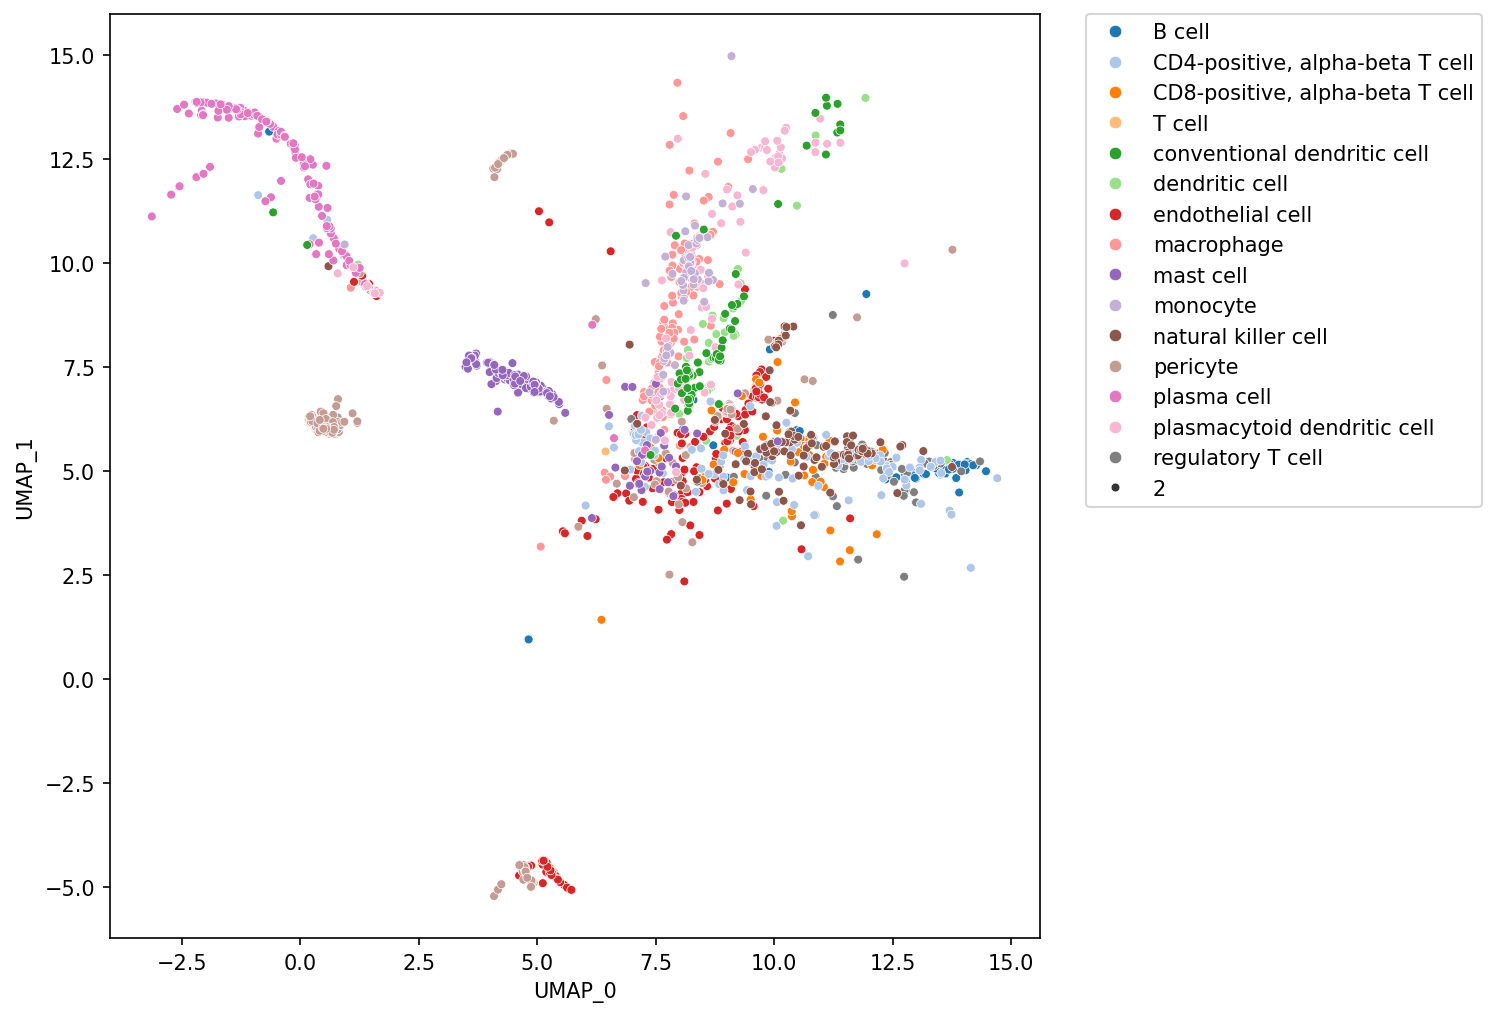

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

fig,ax = plt.subplots(figsize=(8,8),dpi=150)
sns.scatterplot(data=test_dataset.obs[test_dataset.obs['tissue']=='colon'], x="UMAP_0",y="UMAP_1",hue='cell_type',size=2,ax=ax,palette='tab20')
ax.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

### To-Do
1. Add 5% of transcripts from 3 random foreign cell types to all cells